# 03 – Exploratory Data Analysis (EDA)

**Project:** Loyalty and Reward Optimisation with Inventory-Aware Rewards

## Objective
Explore the cleaned Online Retail II transactions to understand sales, customers, products, countries, and purchase-time patterns.

**Input:** `data/interim/cleaned_transactions.csv`  
**Outputs:** EDA summary CSV files and charts saved under `data/interim/eda_outputs/`.

> This notebook only analyses the cleaned data. It does not modify the original Excel file or the cleaned CSV.


## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Find and load the cleaned dataset

In [2]:
# Find the project root by locating the data/interim folder.
current_path = Path.cwd()
project_root = None

for candidate in [current_path, *current_path.parents]:
    if (candidate / "data" / "interim").exists():
        project_root = candidate
        break

if project_root is None:
    raise FileNotFoundError(
        "Could not find data/interim. Open this notebook from inside your project folder."
    )

input_file = project_root / "data" / "interim" / "cleaned_transactions.csv"

if not input_file.exists():
    raise FileNotFoundError(f"Cleaned dataset not found: {input_file}")

df = pd.read_csv(input_file, low_memory=False)

print("Project folder:", project_root)
print("Dataset loaded:", input_file)
print("Rows:", len(df))
print("Columns:", len(df.columns))

display(df.head())

Project folder: d:\loyality_reward_optimization
Dataset loaded: d:\loyality_reward_optimization\data\interim\cleaned_transactions.csv
Rows: 1033036
Columns: 16


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_sheet,is_cancelled,transaction_type,line_amount,is_zero_price,is_negative_price,is_customer_id_missing,is_rfm_eligible
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,Year 2009-2010,False,normal_sale,83.40,False,False,False,True
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010,False,normal_sale,81.00,False,False,False,True
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,Year 2009-2010,False,normal_sale,81.00,False,False,False,True
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,Year 2009-2010,False,normal_sale,100.80,False,False,False,True
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,Year 2009-2010,False,normal_sale,30.00,False,False,False,True


## 3. Prepare output folder and inspect columns

In [3]:
output_dir = project_root / "data" / "interim" / "eda_outputs"
figures_dir = output_dir / "figures"
output_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

print("Available columns:")
print(df.columns.tolist())

Available columns:
['invoice', 'stockcode', 'description', 'quantity', 'invoicedate', 'price', 'customer_id', 'country', 'source_sheet', 'is_cancelled', 'transaction_type', 'line_amount', 'is_zero_price', 'is_negative_price', 'is_customer_id_missing', 'is_rfm_eligible']


## 4. Standardise column names and identify important columns


In [4]:
df.columns = [str(col).strip().lower().replace(" ", "_") for col in df.columns]

def find_column(possible_names):
    for name in possible_names:
        if name in df.columns:
            return name
    return None

invoice_col = find_column(["invoice", "invoiceno", "invoice_no"])
quantity_col = find_column(["quantity", "qty"])
price_col = find_column(["price", "unit_price"])
date_col = find_column(["invoice_date", "invoicedate", "date"])
customer_col = find_column(["customer_id", "customerid", "customer"])
description_col = find_column(["description", "product_description"])
country_col = find_column(["country"])
type_col = find_column(["transaction_type"])
amount_col = find_column(["line_amount", "total_amount", "amount"])

required = {
    "quantity": quantity_col,
    "price": price_col,
    "invoice date": date_col,
    "customer id": customer_col,
    "country": country_col
}
missing_required = [name for name, col in required.items() if col is None]

if missing_required:
    raise ValueError(
        "Required columns not found: " + ", ".join(missing_required) +
        ". Check the column names in the cleaned CSV."
    )

# Convert columns to suitable data types for analysis.
df[quantity_col] = pd.to_numeric(df[quantity_col], errors="coerce")
df[price_col] = pd.to_numeric(df[price_col], errors="coerce")
df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
df[customer_col] = pd.to_numeric(df[customer_col], errors="coerce")

# Calculate line amount if it was not created during cleaning.
if amount_col is None:
    amount_col = "line_amount"
    df[amount_col] = df[quantity_col] * df[price_col]
else:
    df[amount_col] = pd.to_numeric(df[amount_col], errors="coerce")

print("Identified columns:")
print({
    "invoice": invoice_col,
    "quantity": quantity_col,
    "price": price_col,
    "date": date_col,
    "customer": customer_col,
    "description": description_col,
    "country": country_col,
    "transaction_type": type_col,
    "amount": amount_col
})

Identified columns:
{'invoice': 'invoice', 'quantity': 'quantity', 'price': 'price', 'date': 'invoicedate', 'customer': 'customer_id', 'description': 'description', 'country': 'country', 'transaction_type': 'transaction_type', 'amount': 'line_amount'}


## 5. Dataset overview

In [5]:
overview = pd.DataFrame({
    "metric": [
        "Total rows",
        "Total columns",
        "Unique customers",
        "Unique invoices",
        "Unique countries",
        "Unique products/descriptions",
        "Earliest transaction date",
        "Latest transaction date"
    ],
    "value": [
        len(df),
        len(df.columns),
        df[customer_col].nunique(),
        df[invoice_col].nunique() if invoice_col else np.nan,
        df[country_col].nunique(),
        df[description_col].nunique() if description_col else np.nan,
        df[date_col].min(),
        df[date_col].max()
    ]
})

display(overview)
overview.to_csv(output_dir / "eda_dataset_overview.csv", index=False)

,metric,value
0,Total rows,1033036
1,Total columns,16
2,Unique customers,5942
3,Unique invoices,53628
4,Unique countries,43
5,Unique products/descriptions,5655
6,Earliest transaction date,2009-12-01 07:45:00
7,Latest transaction date,2011-12-09 12:50:00


## 6. Missing-value analysis

,missing_count,missing_percentage
customer_id,235151,22.76
description,1181,0.11
stockcode,0,0.00
invoice,0,0.00
quantity,0,0.00
invoicedate,0,0.00
price,0,0.00
country,0,0.00
source_sheet,0,0.00
is_cancelled,0,0.00


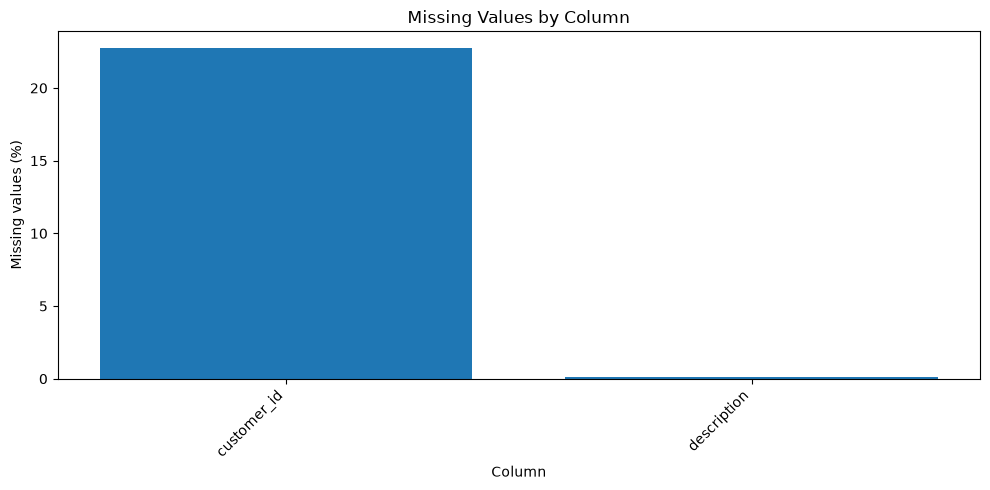

In [6]:
missing_report = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().sum() / len(df) * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_report)
missing_report.to_csv(output_dir / "eda_missing_values.csv")

missing_to_plot = missing_report[missing_report["missing_count"] > 0]

if not missing_to_plot.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(missing_to_plot.index, missing_to_plot["missing_percentage"])
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(figures_dir / "missing_values.png", dpi=150)
    plt.show()
else:
    print("No missing values found.")

## 7. Transaction-type analysis

,transaction_type,record_count,percentage
0,normal_sale,1010539,97.82
1,cancellation,19104,1.85
2,return,3393,0.33


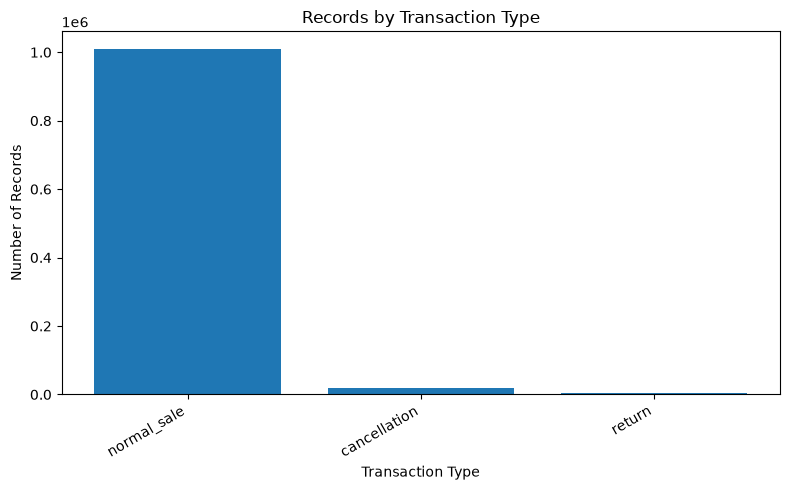

In [7]:
if type_col:
    transaction_summary = (
        df[type_col].fillna("unknown")
        .value_counts()
        .rename_axis("transaction_type")
        .reset_index(name="record_count")
    )
    transaction_summary["percentage"] = (
        transaction_summary["record_count"] / len(df) * 100
    ).round(2)

    display(transaction_summary)
    transaction_summary.to_csv(output_dir / "eda_transaction_types.csv", index=False)

    plt.figure(figsize=(8, 5))
    plt.bar(transaction_summary["transaction_type"], transaction_summary["record_count"])
    plt.title("Records by Transaction Type")
    plt.xlabel("Transaction Type")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(figures_dir / "transaction_types.png", dpi=150)
    plt.show()
else:
    print("transaction_type column not found. Skipping this analysis.")

## 8. Sales analysis


In [8]:
if "is_rfm_eligible" in df.columns:
    sales_df = df[df["is_rfm_eligible"].astype(str).str.lower().isin(["true", "1"])].copy()
else:
    sales_df = df[
        (df[quantity_col] > 0) &
        (df[price_col] > 0) &
        (df[customer_col].notna())
    ].copy()

sales_df[amount_col] = sales_df[quantity_col] * sales_df[price_col]

sales_summary = pd.DataFrame({
    "metric": [
        "Qualifying sales records",
        "Total quantity sold",
        "Total qualifying gross sales",
        "Average line value",
        "Unique customers in qualifying sales",
        "Unique invoices in qualifying sales"
    ],
    "value": [
        len(sales_df),
        sales_df[quantity_col].sum(),
        sales_df[amount_col].sum(),
        sales_df[amount_col].mean(),
        sales_df[customer_col].nunique(),
        sales_df[invoice_col].nunique() if invoice_col else np.nan
    ]
})

display(sales_summary)
sales_summary.to_csv(output_dir / "eda_sales_summary.csv", index=False)

,metric,value
0,Qualifying sales records,"779,425.00"
1,Total quantity sold,"10,513,952.00"
2,Total qualifying gross sales,"17,374,804.27"
3,Average line value,22.29
4,Unique customers in qualifying sales,"5,878.00"
5,Unique invoices in qualifying sales,"36,969.00"


## 9. Monthly sales trend

,month,total_sales,quantity_sold,invoice_count
0,2009-12,"683,504.01",398660,1512
1,2010-01,"555,802.67",370082,1011
2,2010-02,"504,558.96",371861,1104
3,2010-03,"696,978.47",502100,1524
4,2010-04,"591,982.00",350587,1329
5,2010-05,"597,833.38",384960,1377
6,2010-06,"636,371.13",389872,1497
7,2010-07,"589,736.17",324632,1381
8,2010-08,"602,224.60",452542,1293
9,2010-09,"829,013.95",567153,1689


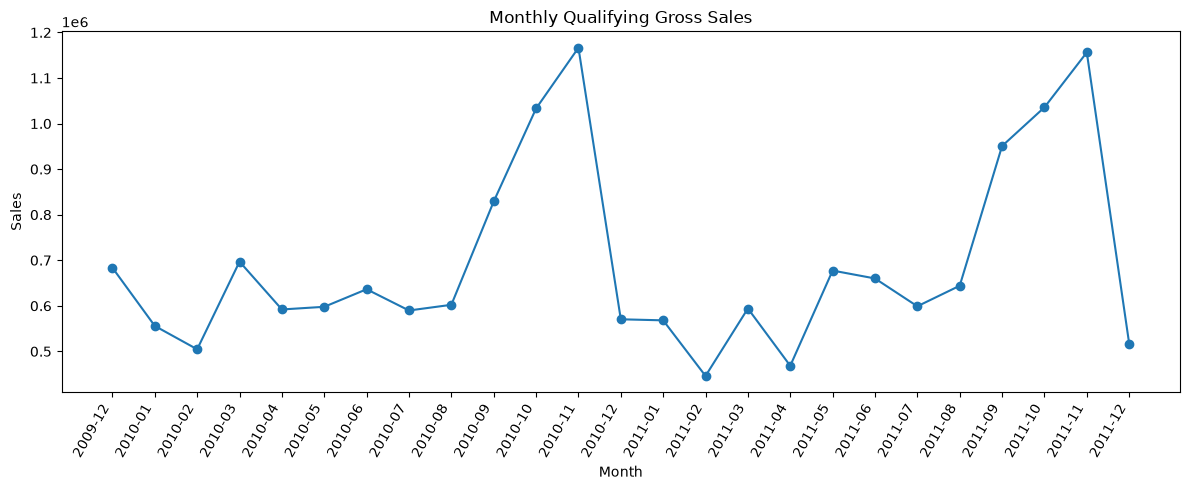

In [9]:
monthly_sales = (
    sales_df.dropna(subset=[date_col])
    .assign(month=lambda data: data[date_col].dt.to_period("M").astype(str))
    .groupby("month", as_index=False)
    .agg(
        total_sales=(amount_col, "sum"),
        quantity_sold=(quantity_col, "sum"),
        invoice_count=(invoice_col, "nunique") if invoice_col else (amount_col, "count")
    )
    .sort_values("month")
)

display(monthly_sales.head(12))
monthly_sales.to_csv(output_dir / "eda_monthly_sales.csv", index=False)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["month"], monthly_sales["total_sales"], marker="o")
plt.title("Monthly Qualifying Gross Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "monthly_sales_trend.png", dpi=150)
plt.show()

## 10. Top countries by sales

,country,total_sales,quantity_sold,unique_customers
38,United Kingdom,"14,389,234.92",8532411,5350
10,EIRE,"616,570.54",318021,5
24,Netherlands,"554,038.09",383879,22
14,Germany,"425,019.71",225154,107
13,France,"348,768.96",270288,95
0,Australia,"169,283.46",103759,15
32,Spain,"108,332.49",50307,41
34,Switzerland,"100,061.94",52227,22
33,Sweden,"91,515.82",88495,19
9,Denmark,"68,580.69",237471,12


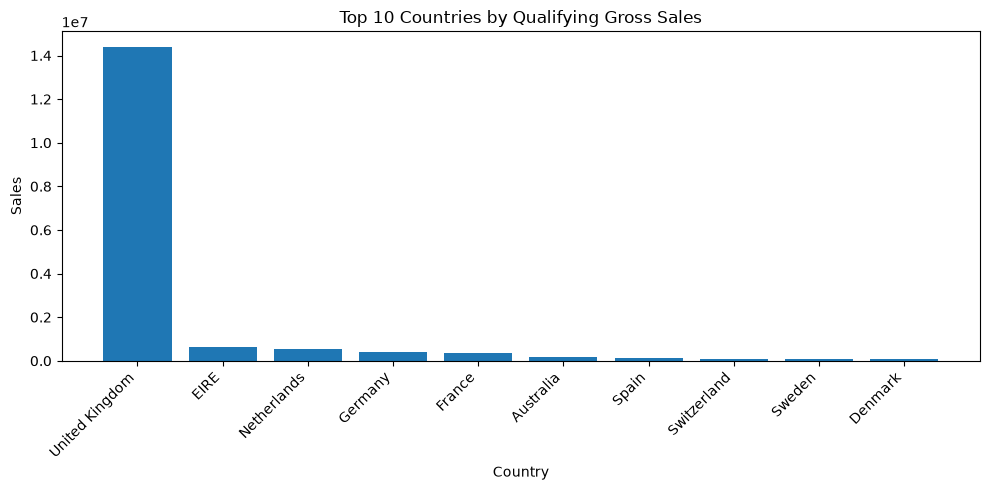

In [10]:
country_sales = (
    sales_df.groupby(country_col, as_index=False)
    .agg(
        total_sales=(amount_col, "sum"),
        quantity_sold=(quantity_col, "sum"),
        unique_customers=(customer_col, "nunique")
    )
    .sort_values("total_sales", ascending=False)
)

top_countries = country_sales.head(10)
display(top_countries)
country_sales.to_csv(output_dir / "eda_country_sales.csv", index=False)

plt.figure(figsize=(10, 5))
plt.bar(top_countries[country_col].astype(str), top_countries["total_sales"])
plt.title("Top 10 Countries by Qualifying Gross Sales")
plt.xlabel("Country")
plt.ylabel("Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "top_countries_sales.png", dpi=150)
plt.show()

## 11. Top products by sales

,description,total_sales,quantity_sold,invoice_count
3726,REGENCY CAKESTAND 3 TIER,"277,656.25",24124,3317
5005,WHITE HANGING HEART T-LIGHT HOLDER,"247,048.01",91757,4888
3090,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1
2819,Manual,"151,777.67",9384,620
2352,JUMBO BAG RED RETROSPOT,"134,307.44",74224,2612
3503,POSTAGE,"124,648.04",5235,1803
257,ASSORTED COLOUR BIRD ORNAMENT,"124,351.86",78234,2652
3115,PARTY BUNTING,"103,283.38",23460,2077
2655,MEDIUM CERAMIC TOP STORAGE JAR,"81,416.73",77916,195
3083,PAPER CHAIN KIT 50'S CHRISTMAS,"76,598.18",28380,1691


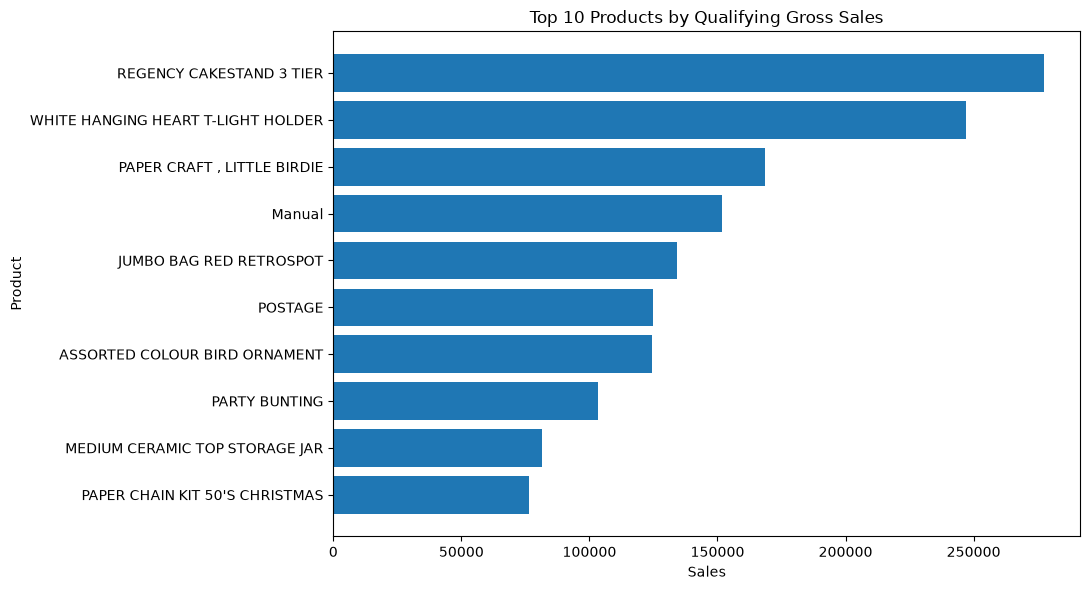

In [11]:
if description_col:
    product_sales = (
        sales_df.groupby(description_col, as_index=False)
        .agg(
            total_sales=(amount_col, "sum"),
            quantity_sold=(quantity_col, "sum"),
            invoice_count=(invoice_col, "nunique") if invoice_col else (amount_col, "count")
        )
        .sort_values("total_sales", ascending=False)
    )

    top_products = product_sales.head(10)
    display(top_products)
    product_sales.to_csv(output_dir / "eda_product_sales.csv", index=False)

    plt.figure(figsize=(11, 6))
    plt.barh(top_products[description_col].astype(str).iloc[::-1],
             top_products["total_sales"].iloc[::-1])
    plt.title("Top 10 Products by Qualifying Gross Sales")
    plt.xlabel("Sales")
    plt.ylabel("Product")
    plt.tight_layout()
    plt.savefig(figures_dir / "top_products_sales.png", dpi=150)
    plt.show()
else:
    print("Product description column not found. Skipping product analysis.")

## 12. Top customers by sales

,customer_id,total_sales,quantity_sold,invoice_count
5692,"18,102.00","580,987.04",181645,145
2277,"14,646.00","528,602.52",367193,151
1789,"14,156.00","313,437.62",164325,156
2538,"14,911.00","291,420.81",147972,398
5050,"17,450.00","244,784.25",83914,51
1331,"13,694.00","195,640.69",188201,143
5109,"17,511.00","172,132.87",117174,60
4061,"16,446.00","168,472.50",80997,2
4295,"16,684.00","147,142.77",104810,55
68,"12,415.00","144,458.37",91447,28


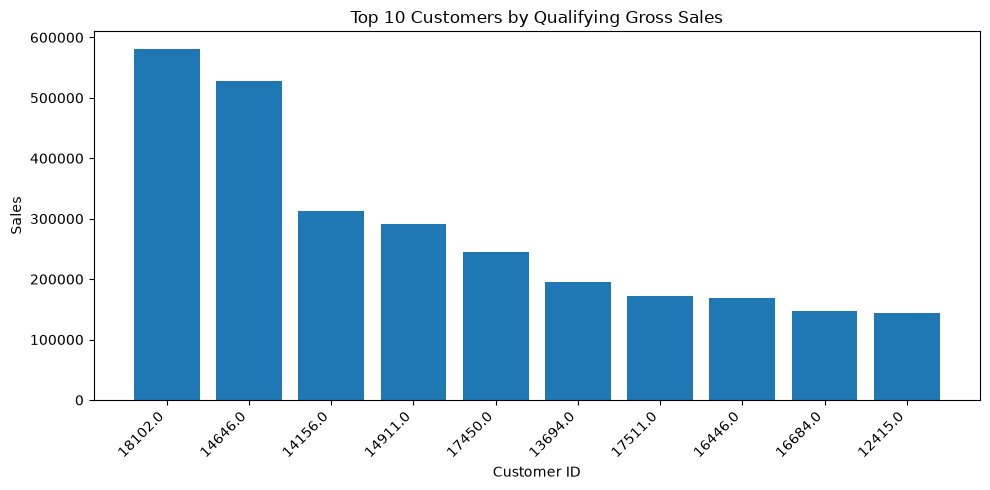

In [12]:
customer_sales = (
    sales_df.groupby(customer_col, as_index=False)
    .agg(
        total_sales=(amount_col, "sum"),
        quantity_sold=(quantity_col, "sum"),
        invoice_count=(invoice_col, "nunique") if invoice_col else (amount_col, "count")
    )
    .sort_values("total_sales", ascending=False)
)

top_customers = customer_sales.head(10)
display(top_customers)
customer_sales.to_csv(output_dir / "eda_customer_sales.csv", index=False)

plt.figure(figsize=(10, 5))
plt.bar(top_customers[customer_col].astype(str), top_customers["total_sales"])
plt.title("Top 10 Customers by Qualifying Gross Sales")
plt.xlabel("Customer ID")
plt.ylabel("Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "top_customers_sales.png", dpi=150)
plt.show()

## 13. Purchase-time patterns

,day_of_week,total_sales,invoice_count
1,Monday,"2,778,201.57",5755
5,Tuesday,"3,322,830.14",6627
6,Wednesday,"3,021,043.85",6649
4,Thursday,"3,745,783.43",7773
0,Friday,"2,728,473.17",5387
2,Saturday,"9,803.05",30
3,Sunday,"1,768,669.05",4748


,hour,total_sales,invoice_count
0,6,4.25,1
1,7,"75,745.57",76
2,8,"524,612.55",979
3,9,"1,484,450.54",2548
4,10,"2,320,711.44",4364
5,11,"2,235,870.39",4609
6,12,"2,690,583.50",6170
7,13,"2,347,078.71",5418
8,14,"1,962,016.16",4559
9,15,"1,839,607.76",3992


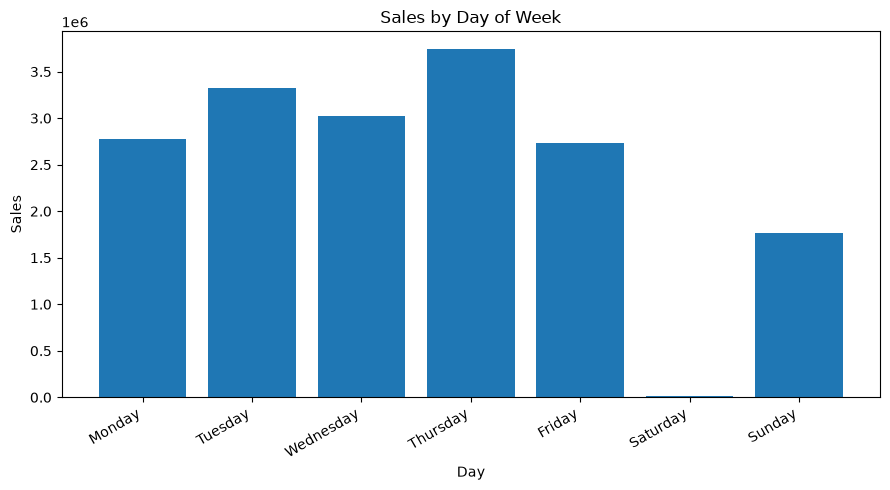

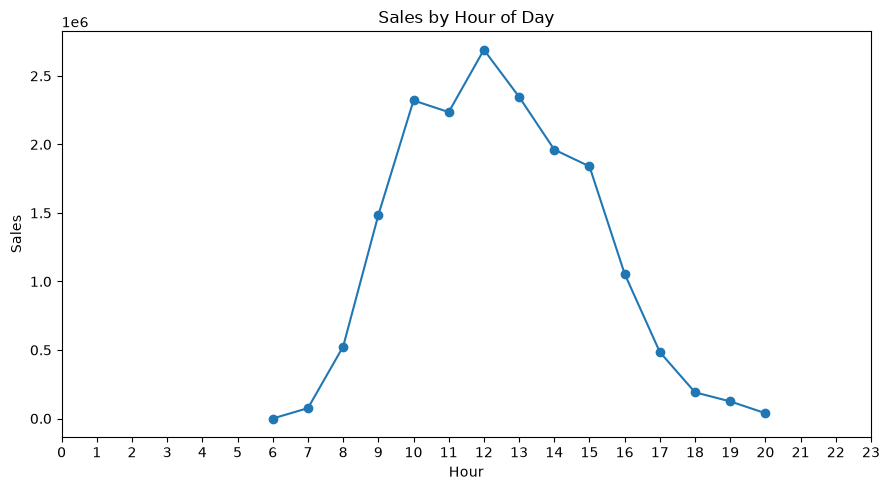

In [13]:
time_df = sales_df.dropna(subset=[date_col]).copy()
time_df["day_of_week"] = time_df[date_col].dt.day_name()
time_df["hour"] = time_df[date_col].dt.hour

weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_sales = (
    time_df.groupby("day_of_week", as_index=False)
    .agg(total_sales=(amount_col, "sum"), invoice_count=(invoice_col, "nunique")
         if invoice_col else (amount_col, "count"))
)
weekday_sales["day_of_week"] = pd.Categorical(
    weekday_sales["day_of_week"], categories=weekday_order, ordered=True
)
weekday_sales = weekday_sales.sort_values("day_of_week")

hourly_sales = (
    time_df.groupby("hour", as_index=False)
    .agg(total_sales=(amount_col, "sum"), invoice_count=(invoice_col, "nunique")
         if invoice_col else (amount_col, "count"))
)

display(weekday_sales)
display(hourly_sales)

weekday_sales.to_csv(output_dir / "eda_weekday_sales.csv", index=False)
hourly_sales.to_csv(output_dir / "eda_hourly_sales.csv", index=False)

plt.figure(figsize=(9, 5))
plt.bar(weekday_sales["day_of_week"].astype(str), weekday_sales["total_sales"])
plt.title("Sales by Day of Week")
plt.xlabel("Day")
plt.ylabel("Sales")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(figures_dir / "sales_by_weekday.png", dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(hourly_sales["hour"], hourly_sales["total_sales"], marker="o")
plt.title("Sales by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Sales")
plt.xticks(range(0, 24))
plt.tight_layout()
plt.savefig(figures_dir / "sales_by_hour.png", dpi=150)
plt.show()

## 14. Numeric feature distributions

,count,mean,std,min,25%,50%,75%,max
quantity,"779,425.00",13.49,145.86,1.00,2.00,6.00,12.00,"80,995.00"
price,"779,425.00",3.22,29.68,0.00,1.25,1.95,3.75,"10,953.50"
line_amount,"779,425.00",22.29,227.43,0.00,4.95,12.48,19.80,"168,469.60"


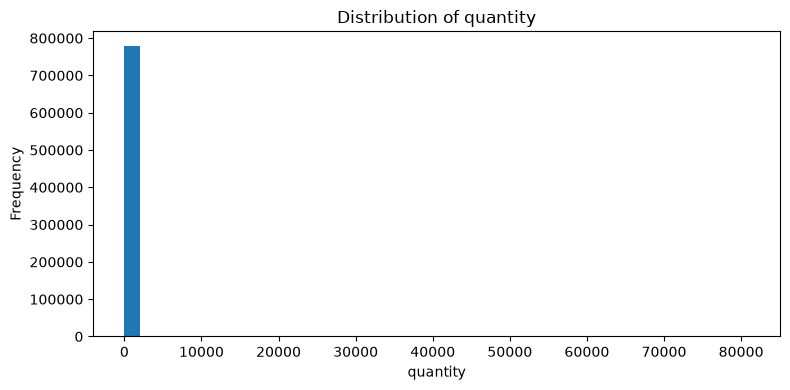

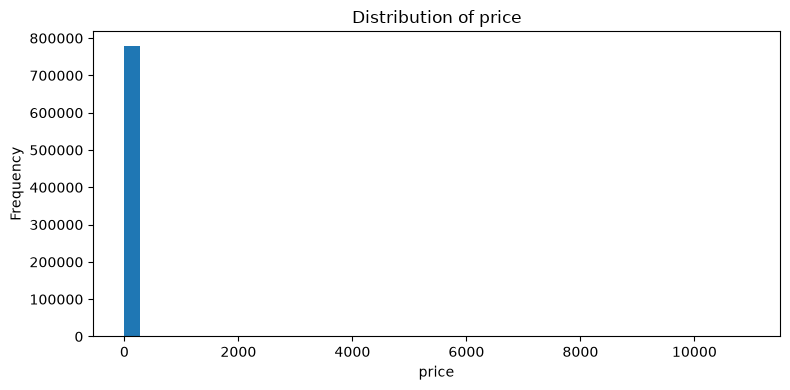

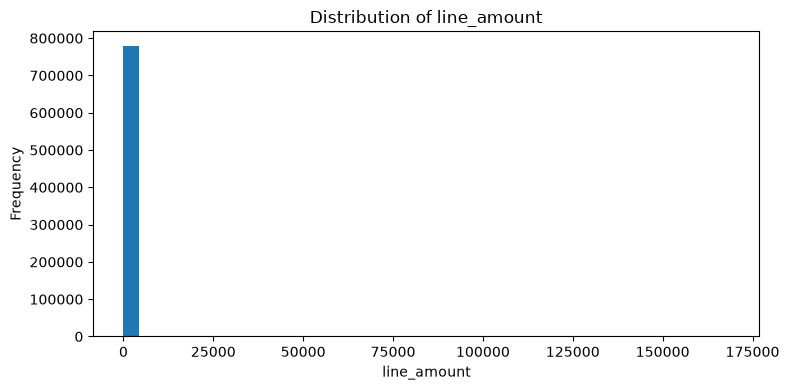

In [14]:
numeric_columns = [quantity_col, price_col, amount_col]
numeric_data = sales_df[numeric_columns].replace([np.inf, -np.inf], np.nan).dropna()

display(numeric_data.describe().T)

for column in numeric_columns:
    plt.figure(figsize=(8, 4))
    plt.hist(numeric_data[column], bins=40)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.savefig(figures_dir / f"distribution_{column}.png", dpi=150)
    plt.show()

## 15. Save key findings

In [15]:
key_findings = {
    "total_cleaned_records": int(len(df)),
    "qualifying_sales_records": int(len(sales_df)),
    "unique_customers": int(sales_df[customer_col].nunique()),
    "unique_invoices": int(sales_df[invoice_col].nunique()) if invoice_col else None,
    "total_qualifying_gross_sales": float(sales_df[amount_col].sum()),
    "top_country_by_sales": str(country_sales.iloc[0][country_col]) if len(country_sales) else None,
    "top_product_by_sales": str(product_sales.iloc[0][description_col])
        if description_col and "product_sales" in globals() and len(product_sales) else None
}

findings_df = pd.DataFrame(
    [{"finding": key, "value": value} for key, value in key_findings.items()]
)
display(findings_df)
findings_df.to_csv(output_dir / "eda_key_findings.csv", index=False)

print("EDA outputs saved in:", output_dir)
print("Charts saved in:", figures_dir)

,finding,value
0,total_cleaned_records,1033036
1,qualifying_sales_records,779425
2,unique_customers,5878
3,unique_invoices,36969
4,total_qualifying_gross_sales,"17,374,804.27"
5,top_country_by_sales,United Kingdom
6,top_product_by_sales,REGENCY CAKESTAND 3 TIER


EDA outputs saved in: d:\loyality_reward_optimization\data\interim\eda_outputs
Charts saved in: d:\loyality_reward_optimization\data\interim\eda_outputs\figures
